# Predição de óbito ou readmissão em 6 meses em pacientes com insuficiência cardíaca

Trabalho final de Inteligência Computacional Aplicada a Problemas de Engenharia (UFMG 2026/2).

**Objetivo**: a partir das informações disponíveis na internação, prever se o paciente terá **óbito ou readmissão hospitalar em até 6 meses** (classificação binária).

Este *notebook* funciona como o **painel executivo** do projeto. Toda a lógica pesada de processamento de dados e engenharia de atributos foi modularizada para os ficheiros Python `.py` na pasta `src/`, garantindo um ambiente limpo e focado na análise científica e clínica.

## Sobre a base de dados

**Hospitalized patients with heart failure: integrating electronic healthcare records and external outcome data**, versão 1.3 (22/05/2022), PhysioNet.

- **Origem**: prontuários eletrônicos do *Zigong Fourth People's Hospital* (Sichuan, China), internações entre **dezembro/2016 e junho/2019**.
- **População**: **2008 pacientes** internados consecutivamente com insuficiência cardíaca (IC), diagnosticada pelos critérios da *European Society of Cardiology*.
- **Conteúdo** (`dat.csv`): dados demográficos e de admissão, sinais vitais, classificação da IC (tipo, NYHA, Killip), comorbidades (índice de Charlson), nível de consciência (Glasgow), ecocardiograma, ~100 exames laboratoriais e **desfechos de seguimento**.
- **Medicamentos** (`dat_md.csv`): fármacos administrados durante a internação (diuréticos, inotrópicos, vasodilatadores, etc.), em formato longo.

**Como citar:** Zhang, Z., Cao, L., Zhao, Y., Xu, Z., Chen, R., Lv, L., & Xu, P. (2022). *Hospitalized patients with heart failure: integrating electronic healthcare records and external outcome data* (version 1.3). PhysioNet. https://doi.org/10.13026/5m60-vs44

## 0. Configurações Iniciais

Utilizamos o módulo `src/utils.py` para padronizar diretórios, variáveis globais e temas de plotagem (Matplotlib/Seaborn). Isso mantém o início do notebook limpo.

In [4]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Adiciona a raiz do repositório ao sys.path
BASE_DIR = Path.cwd().resolve().parent
if str(BASE_DIR) not in sys.path:
    sys.path.append(str(BASE_DIR))

# Importações dos módulos customizados
from src import utils, preprocessing, features, eda

# Aplica o tema visual padronizado para gráficos
utils.setup_plotting()

## 1. Carregamento dos Dados

Os dados brutos são carregados através da função `load_data()` do módulo `preprocessing.py`. Ela obtém os dados clínicos (`dat.csv`), a tabela de medicamentos (`dat_md.csv`) e o dicionário de variáveis.

In [5]:
patients, drugs, data_dictionary = preprocessing.load_data()

print(f"Base clínica (pacientes): {patients.shape}")
print(f"Base de medicamentos: {drugs.shape}")

Base clínica (pacientes): (2008, 166)
Base de medicamentos: (15362, 2)


### 1.1 Dicionário de Variáveis

As 166 colunas de `dat.csv` foram agrupadas por temas clínicos (Demografia, Sinais Vitais, Exames Laboratoriais, Desfechos) pelo dicionário de dados. O módulo `preprocessing.py` mapeia esses agrupamentos em `get_variable_groups()` para facilitar a visualização e filtragem (ex: remoção de dados de alta).

In [6]:
variable_groups = preprocessing.get_variable_groups(patients)
print(f"Foram definidos {len(variable_groups)} grupos de variáveis.")

Foram definidos 18 grupos de variáveis.


### 1.1.1 Resumo Visual do Dicionário (Tabela 1)

Através do módulo `eda.py`, conseguimos gerar a tabela que mapeia todos os campos, a quantidade de dados em falta e os valores observados para cada variável clínica.

In [7]:
from src import eda

overview = eda.generate_variable_overview(patients, data_dictionary, variable_groups)
eda.display_variable_overview(overview)

Resumo por Grupo Clínico:


,n_variáveis,faltantes_médio,faltantes_máx
grupo,,,
Identificação,1,0.0,0.0
Demografia,3,0.4,1.3
Admissão e histórico,3,0.0,0.0
Sinais vitais e antropometria,9,0.0,0.0
Classificação da IC,3,0.0,0.0
Comorbidades,17,0.0,0.2
Estado clínico na admissão,10,9.8,97.9
Ecocardiograma,7,65.6,90.9
Lab. — função renal,5,1.7,3.1


#### Identificação

,descrição,tipo,faltantes (%),valores observados
variável,,,,
inpatient.number,The patient unique ID,numérica,0.0,722128 – 798758 – 905720


#### Demografia

,descrição,tipo,faltantes (%),valores observados
variável,,,,
occupation,occupation,categórica,1.3,"Officer, Others, UrbanResident, farmer, worker"
gender,"gender: Male, Female",binária,0.0,"Female, Male"
ageCat,ageCat:the age is categorized in decades,categórica,0.0,"(21,29], (29,39], (39,49], (49,59], (59,69], (69,79], (79,89], (89,110]"


... (28 outputs left out)

#### Desfechos e seguimento

,descrição,tipo,faltantes (%),valores observados
variável,,,,
outcome.during.hospitalization,"outcome during hospitalization, recorded after the decision of discharge was made ( living vs. died in the hospital)",categórica,0.0,"Alive, Dead, DischargeAgainstOrder"
death.within.28.days,death.within.28.days,binária,0.0,"0, 1"
re.admission.within.28.days,re.admission.within.28.days,binária,0.0,"0, 1"
death.within.3.months,death.within.3.months,binária,0.0,"0, 1"
re.admission.within.3.months,re.admission.within.3.months,binária,0.0,"0, 1"
death.within.6.months,death.within.6.months,binária,0.0,"0, 1"
re.admission.within.6.months,re.admission.within.6.months,binária,0.0,"0, 1"
time.of.death..days.from.admission.,time.of.death..days.from.admission.,numérica,97.8,1 – 4.5 – 350
re.admission.time..days.from.admission.,re.admission.time..days.from.admission.,numérica,55.1,1 – 83 – 2280


#### Informações da alta

,descrição,tipo,faltantes (%),valores observados
variável,,,,
DestinationDischarge,"Destination of hospital discharge, recorded after discharge",categórica,0.0,"Died, HealthcareFacility, Home, Unknown"
discharge.department,the patient discharged from,categórica,0.0,"Cardiology, GeneralWard, ICU, Others"
dischargeDay,dischargeDay: days from admission to hospital discharge,numérica,0.0,1 – 8 – 123


### 1.2 Medicamentos (`dat_md.csv`)

A base de medicamentos encontra-se num **formato longo** (uma linha por par paciente-fármaco). Nesta versão, a informação disponível é apenas binária: **usou ou não usou** determinado fármaco, sem dosagem nem frequência.

### 1.3 Valores Faltantes

Nem todo `NA` é um dado perdido aleatoriamente (Missing At Random). Exames como gasometria e perfil lipídico costumam faltar em blocos, indicando que **o painel não foi pedido**. Como essa ausência carrega informação clínica (o médico julgou desnecessário), utilizaremos indicadores de falta (*missing flags*) na etapa de Engenharia de Atributos em vez de apenas imputar os valores.

### 1.4 Variável Alvo: Óbito ou Readmissão em 6 meses

**Por que este alvo**: O desfecho composto (óbito ou readmissão em 6 meses) é o *endpoint* mais utilizado em estudos de prognóstico de IC. Ele contorna um viés sério da readmissão isolada: quem falece após a alta não pode ser readmitido e seria falsamente contabilizado como um caso de 'sucesso' se usássemos apenas a readmissão. 

A função `create_target()` do módulo `preprocessing.py` realiza o agrupamento destas variáveis.

In [8]:
target = preprocessing.create_target(patients)

print(f"Total no alvo: {target.sum()} de {len(target)} ({target.mean():.1%})")

Total no alvo: 833 de 2008 (41.5%)


### 1.3.1 Matriz de Valores Faltantes

Esta visualização comprova o padrão NMAR (Not Missing At Random). As faixas que atravessam o painel confirmam que não faltam pontos aleatórios de dados, mas sim painéis inteiros que não foram solicitados pelo médico.

Figura salva em: /home/luishcr/iic_projeto_final/heart-failure-outcome-prediction-fork1/results/figures/missing_matrix.pdf


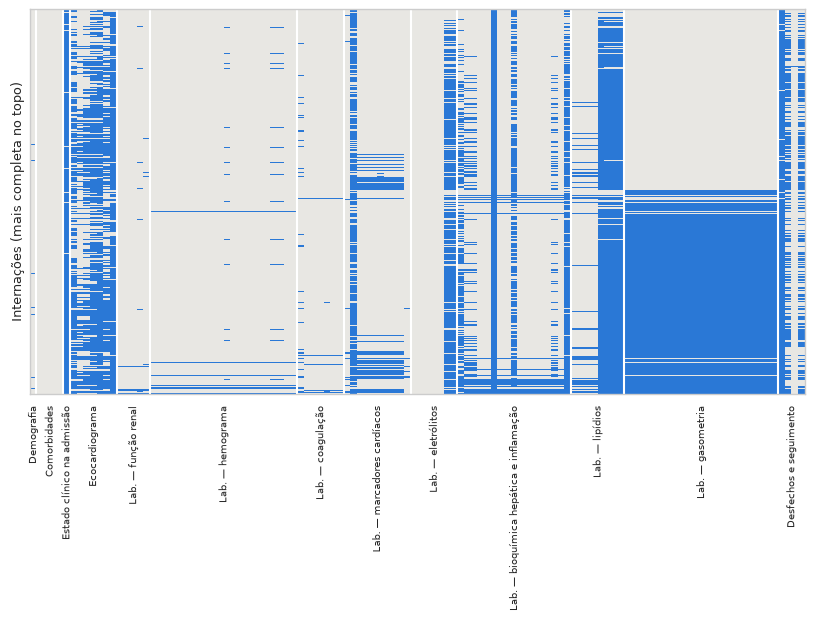

In [9]:
eda.plot_missing_matrix(patients, variable_groups)

## 2. Extração e Engenharia de Atributos

A função `features.build_feature_set()` executa três passos críticos de forma limpa e modular:
1. **Remoção de Vazamento de Informação (Data Leakage)**: Remove desfechos temporais e informações exclusivas do momento da alta.
2. **Missing Flags**: Cria colunas indicadoras binárias (ex: `coluna_is_missing = 1`) para exames com mais de 20% de valores nulos.
3. **Pivotamento de Medicamentos**: Transforma a base `dat_md.csv` para o formato *wide*, em que cada fármaco se torna uma coluna binária acoplada à base clínica.

In [10]:
# Orquestração do pipeline de limpeza e feature engineering
X = features.build_feature_set(patients, drugs, variable_groups)

print(f"Dimensão do conjunto de features final (X): {X.shape}")
X.head()

Removidas 15 colunas de vazamento. Restam 151 atributos clínicos.
Adicionados 45 indicadores de dados em falta (threshold > 20.0%).
Base de medicamentos processada: 25 fármacos extraídos.
Dimensão do conjunto de features final (X): (2008, 221)


,admission.ward,admission.way,occupation,visit.times,gender,body.temperature,pulse,respiration,systolic.blood.pressure,diastolic.blood.pressure,map,weight,height,BMI,type.of.heart.failure,NYHA.cardiac.function.classification,Killip.grade,myocardial.infarction,congestive.heart.failure,peripheral.vascular.disease,cerebrovascular.disease,dementia,Chronic.obstructive.pulmonary.disease,connective.tissue.disease,peptic.ulcer.disease,...,drug_Aspirin enteric-coated tablet,drug_Atorvastatin calcium tablet,drug_Benazepril hydrochloride tablet,drug_Clopidogrel Hydrogen Sulphate tablet,drug_Deslanoside injection,drug_Digoxin tablet,drug_Dobutamine hydrochloride injection,drug_Enoxaparin Sodium injection,drug_Furosemide injection,drug_Furosemide tablet,drug_Heparin Sodium injection,drug_Hydrochlorothiazide tablet,drug_Isoprenaline Hydrochloride injection,drug_Isosorbide Mononitrate Sustained Release tablet,drug_Meglumine Adenosine Cyclophosphate for injection,drug_Metoprolol Succinate Sustained-release tablet,drug_Milrinone injection,drug_Nitroglycerin injection,drug_Shenfu injection,drug_Spironolactone tablet,drug_Torasemide tablet,drug_Valsartan Dispersible tablet,drug_metoprolol tartrate injection,drug_sulfotanshinone sodium injection,drug_warfarin sodium tablet
1,Cardiology,NonEmergency,UrbanResident,1,Male,36.7,87,19,102,64,76.666667,50.0,1.64,18.590125,Both,III,III,0,0,0,0,0,1,0,0.0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,Cardiology,NonEmergency,UrbanResident,1,Female,36.8,95,18,150,70,96.666667,51.0,1.63,19.195303,Both,III,I,0,0,0,0,0,0,0,0.0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,Cardiology,NonEmergency,farmer,2,Male,36.5,98,18,102,67,78.666667,70.0,1.70,24.221453,Both,II,II,0,0,0,0,0,0,0,0.0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,Cardiology,Emergency,UrbanResident,1,Male,36.0,73,19,110,74,86.000000,65.0,1.70,22.491349,Both,III,II,0,0,0,0,0,1,0,0.0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,Cardiology,NonEmergency,UrbanResident,1,Female,35.0,88,19,134,62,86.000000,76.0,1.55,31.633715,Both,III,II,0,0,0,0,0,0,0,0.0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 3. Treinamento e Avaliação de Modelos

*(Esta secção será preenchida nas próximas fases do plano, importando os módulos `train.py` e `evaluate.py` para treinar os algoritmos e plotar as Curvas ROC e PR)*.